# NeuroContour

**Brain tumor segmentation with a U-Net, tuned in stages · Jacob Russ · MTH 4320 · Project 2**

## Introduction

**The question.** Can a U-Net accurately outline a whole glioma on a single 2D MRI slice — and can a staged search, each experiment chosen from the last one's results, beat one baseline configuration?

**The data.** The BraTS 2020 dataset, from the Brain Tumor Segmentation (BraTS) challenge, accessed through Kaggle: pre-operative glioma MRI gathered from 19 institutions. Each labeled case is one patient with four co-registered MRI volumes (T1, T1ce, T2, FLAIR) at 240×240×155, plus a manual tumor outline approved by neuro-radiologists. The outline marks three sub-regions (labels 1, 2, and 4); this project collapses them into one binary whole-tumor mask. Of the 369 labeled cases, this project uses the first 75, and keeps only the slices that carry at least 50 tumor pixels — 4,724 slices in total.

**The plan.** Part 1 prepares the data and splits it by patient (52 train / 11 validation / 12 test), so no brain ever appears in two splits. Part 2 builds the U-Net and its training code. Part 3 runs the experiments in stages — learning rate first, then a baseline, then one change at a time (loss, augmentation), then an ablation that removes the skip connections. Part 4 touches the test set exactly once, with the winning configuration. The score throughout is the Dice coefficient, the overlap between the predicted and expert outlines, averaged per patient.

## Part 1 — Data preparation

Everything in this part exists to make the later results believable: the right 75 cases, a mask definition that matches the question, slices worth training on, a split that cannot leak, and one dishonest baseline exposed before any model is trained.

**Code cell 1 — Imports and fixed settings**

Bring in the libraries the whole notebook uses (pathlib, random, numpy, nibabel, torch, matplotlib) and set the fixed settings every later cell shares: where the data lives, the 75 case numbers, the slice-keeping rule, image size, batch size, seed, and epoch limits. Settings are set once, here, so every run below is reproducible.

In [4]:
# imports
from pathlib import Path
import csv
import random
import numpy as np
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# fixed settings for project
DATA_ROOT = Path("data") # the case folders live directly under this folder
FIRST_CASE, LAST_CASE = 1, 75 # BraTS_Training_001 to BraTS_Training_075
MIN_TUMOR_PIXELS = 50 # a slice needs at least this much tumor to count
IMG_SIZE = 128 # slices are resized to 128 x 128
BATCH_SIZE = 8 # number of slices per batch
SEED = 42 # random seed for reproducibility
MAX_EPOCHS = 20 # maximum number of epochs to train for
PATIENCE = 5 # number of epochs to wait for validation loss to improve before stopping

# outputs: every figure and table the notebook makes lands here
OUTPUT_DIR = Path("outputs") 
FIG_DIR = OUTPUT_DIR / "figures"


**Code cell 2 — Seed and device**

Fix the random seeds (Python, numpy, torch) and pick the compute device — MPS on an Apple-silicon Mac, CUDA if present, otherwise CPU — then print both so the choice is visible in the output.

In [5]:
random.seed(SEED)
np.random.seed(SEED) 
torch.manual_seed(SEED)

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


Device: mps


**Code cell 3 — Find the 75 cases**

Starting from the data root, build the sorted list of case folders for BraTS20_Training_001 through BraTS20_Training_075 and print how many were found, plus the first and last names.

In [15]:
root = DATA_ROOT
for i in range(FIRST_CASE, LAST_CASE + 1):
    one_case = root / f"BraTS20_Training_{i:03d}"
    assert one_case.exists(), f"Case folder {one_case} does not exist"

entries = list(DATA_ROOT.iterdir())
print(sorted([e.name for e in entries]))

kept = []
for e in entries: 
    if not e.name.startswith("BraTS20_Training_"): 
        continue  # not a case name skip it
    number = int(e.name[len("BraTS20_Training_"):]) # the number of the case
    if FIRST_CASE <= number <= LAST_CASE: # in the range we want?
        kept.append(e)

case_dirs = sorted(kept, key=lambda e: e.name)
print(len(case_dirs)) # 75
print(case_dirs[0].name) # first case folder
print(case_dirs[-1].name) # last case folder



['.DS_Store', 'BraTS20_Training_001', 'BraTS20_Training_002', 'BraTS20_Training_003', 'BraTS20_Training_004', 'BraTS20_Training_005', 'BraTS20_Training_006', 'BraTS20_Training_007', 'BraTS20_Training_008', 'BraTS20_Training_009', 'BraTS20_Training_010', 'BraTS20_Training_011', 'BraTS20_Training_012', 'BraTS20_Training_013', 'BraTS20_Training_014', 'BraTS20_Training_015', 'BraTS20_Training_016', 'BraTS20_Training_017', 'BraTS20_Training_018', 'BraTS20_Training_019', 'BraTS20_Training_020', 'BraTS20_Training_021', 'BraTS20_Training_022', 'BraTS20_Training_023', 'BraTS20_Training_024', 'BraTS20_Training_025', 'BraTS20_Training_026', 'BraTS20_Training_027', 'BraTS20_Training_028', 'BraTS20_Training_029', 'BraTS20_Training_030', 'BraTS20_Training_031', 'BraTS20_Training_032', 'BraTS20_Training_033', 'BraTS20_Training_034', 'BraTS20_Training_035', 'BraTS20_Training_036', 'BraTS20_Training_037', 'BraTS20_Training_038', 'BraTS20_Training_039', 'BraTS20_Training_040', 'BraTS20_Training_041', 'B

**Code cell 4 — Inspect one case folder**

List the files inside the first case folder and print them. A complete case has exactly five files: the four modality scans and the one segmentation file. Note the exact file suffix your copy uses, because the loading code has to match it.

In [16]:
entries = list(case_dirs[0].iterdir())
print(sorted([e.name for e in entries])) # the files in the first case folder



['BraTS20_Training_001_flair.nii', 'BraTS20_Training_001_seg.nii', 'BraTS20_Training_001_t1.nii', 'BraTS20_Training_001_t1ce.nii', 'BraTS20_Training_001_t2.nii']


**Code cell 5 — Load one case**

Load all five volumes of the first case with nibabel and print each array's shape. Every volume should read (240, 240, 155).

In [19]:
path_f = case_dirs[0] / "BraTS20_Training_001_flair.nii"
path_seg = case_dirs[0] / "BraTS20_Training_001_seg.nii"
path_t1 = case_dirs[0] / "BraTS20_Training_001_t1.nii"
path_t1ce = case_dirs[0] / "BraTS20_Training_001_t1ce.nii"
path_t2 = case_dirs[0] / "BraTS20_Training_001_t2.nii"

volumes = {}

# Loading files
volumes["flair"] = nib.load(path_f).get_fdata()
volumes["seg"] = nib.load(path_seg).get_fdata()
volumes["t1"] = nib.load(path_t1).get_fdata()
volumes["t1ce"] = nib.load(path_t1ce).get_fdata()
volumes["t2"] = nib.load(path_t2).get_fdata()

# Printing Shapes
print(volumes["flair"].shape)
print(volumes["seg"].shape)
print(volumes["t1"].shape)
print(volumes["t1ce"].shape)
print(volumes["t2"].shape)


(240, 240, 155)
(240, 240, 155)
(240, 240, 155)
(240, 240, 155)
(240, 240, 155)


**Code cell 6 — Look at the labels**

Print the distinct label values present in the first case's segmentation, and the number of tumor pixels (any label above zero) on a few example slices. The values should come only from 0, 1, 2, and 4.

[0. 1. 2. 4.]
 211979 total tumors
 3906 tumors at slice 60
 4453 tumors at slice 78
 1508 tumors at slice 100
 Winning slice index: 67


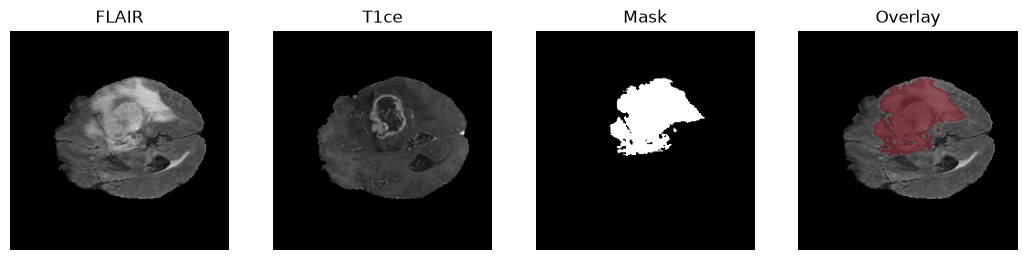

In [37]:
# Collecting and printing unique values in the sseg array
unique = np.unique(volumes["seg"])
print(unique)

# Creating a whole tumor mask and printing its total
mask = volumes["seg"] > 0 
print(f" {mask.sum()} total tumors")

# Printing the tumor count for three single slices
print(f" {mask[:, :, 60].sum()} tumors at slice 60")
print(f" {mask[:, :, 78].sum()} tumors at slice 78")
print(f" {mask[:, :, 100].sum()} tumors at slice 100")

# Sum mask over axes 0 and 1 and save the max

per_slice = mask.sum(axis=(0,1))
max_count = np.argmax(per_slice)
print(F" Winning slice index: {max_count}")

# Cut three slices to plot

flair_slice = volumes["flair"][:, :, 67]
t1ce_slice = volumes["t1ce"][:, :, 67]
mask_slice = mask[:, :, 67]

# Make canvas 
fig, axes = plt.subplots(1, 4, figsize=(13, 4))

# Dropping in the scans
axes[0].imshow(flair_slice, cmap="gray")
axes[1].imshow(t1ce_slice, cmap="gray")
axes[2].imshow(mask_slice, cmap="gray")
axes[3].imshow(flair_slice, cmap="gray")
axes[3].imshow(np.ma.masked_where(mask_slice == 0, mask_slice), cmap="Reds", alpha=0.6, vmin=0, vmax=1)

# Titles 
axes[0].set_title("FLAIR")
axes[1].set_title("T1ce")
axes[2].set_title("Mask")
axes[3].set_title("Overlay")

# remove tick marks
for ax in axes:
    ax.axis("off")

# Save Figure and Plot
plt.savefig(FIG_DIR / "slice_preview.png", dpi=150)
plt.show()


**Code cell 7 — Build the slice index**

Loop over all 75 cases. For each one, load only the segmentation volume, count tumor pixels on every slice, and record (case, slice number) for every slice with at least 50 tumor pixels. This list is the dataset every later cell draws from.

In [42]:
index = []
per_case = []

for path in case_dirs:
    case_name = path.name
    seg = nib.load(path / f"{case_name}_seg.nii").get_fdata()
    counts = (seg > 0).sum(axis=(0, 1))
    kept_here = 0
    for z in range(155):  
        if counts[z] >= MIN_TUMOR_PIXELS:
            index.append((case_name, z))
            kept_here += 1
    per_case.append(kept_here)
print(per_case)

[80, 52, 49, 64, 48, 74, 48, 46, 77, 52, 67, 44, 55, 60, 76, 75, 74, 52, 49, 77, 41, 62, 51, 85, 58, 73, 69, 32, 63, 79, 77, 43, 66, 65, 54, 33, 68, 80, 50, 69, 79, 64, 48, 60, 74, 49, 85, 43, 73, 66, 80, 55, 77, 69, 58, 67, 56, 64, 48, 56, 39, 78, 38, 81, 35, 73, 82, 48, 88, 90, 73, 83, 47, 75, 86]


**Code cell 8 — Check the slice index**

Print the total number of kept slices and the smallest, largest, and average kept-slice counts per case. The total should be 4,724.

In [46]:
# Print total 
print(f" Number of tumor-bearing slices: {len(index)}")

# Print smallest and largest values in per_case
print(f" The smallest value is {min(per_case)}")
print(f" The largest value is {max(per_case)}")

# Print the mean of per_case
print(f" The mean is {np.mean(per_case)}")

 Number of tumor-bearing slices: 4724
 The smallest value is 32
 The largest value is 90
 The mean is 62.986666666666665


**Code cell 9 — Split the patients**

Shuffle the 75 case names with the project seed and divide them into 52 training, 11 validation, and 12 test cases. Store the three lists. The split is by patient, never by slice.

In [62]:
cases = list(case_dirs)
random.Random(42).shuffle(cases)

train_cases, val_cases, test_cases = cases[:52], cases[52:63], cases[63:]

**Code cell 10 — Check the split**

Prove the split is clean: print the three patient counts, confirm no case appears in more than one list, and count how many kept slices fall in each split. The three slice counts must add back up to the index total.

In [ ]:
train_cases = [p.name for p in train_cases]
val_cases = [p.name for p in val_cases]
test_cases = [p.name for p in test_cases]

# Checking for overlap
print((set(train_cases) & set(val_cases)), set(train_cases) & set(test_cases), set(val_cases) & set(test_cases))

# Making sure slices aren't lost 
n_train = sum(1 for name, z in index if name in train_cases)
n_val = sum(1 for name, z in index if name in val_cases)
n_test = sum(1 for name, z in index if name in test_cases)
print(n_train, n_val, n_test)
print(n_train + n_val + n_test)


set() set() set()
3375 685 664
4724


**Code cell 11 — The honest baseline**

Score a predictor that outputs 'no tumor anywhere' against the real validation masks: compute its Dice and its pixel accuracy. Dice should be exactly 0 while accuracy sits near 98% — the reason this project never headlines accuracy.

In [68]:
total = 0
tumor = 0 
for name in val_cases:
    seg = nib.load(DATA_ROOT / name / f"{name}_seg.nii").get_fdata()    
    mask = seg > 0 
    for z in range(seg.shape[2]):
        if (name, z) not in index: 
            continue 
        total += mask[:, :, z].size
        tumor += mask[:, :, z].sum()

accuracy = (total - tumor) / total
overlap = 0 
pred_tumor = 0
dice = 2 * overlap / (pred_tumor + tumor)
print(f"total pixels = {total}")
print(f"tumor pixels = {tumor}")
print(f"accuracy = {accuracy:.2f}")
print(f"dice = {dice:.2f}")

total pixels = 39456000
tumor pixels = 964652
accuracy = 0.98
dice = 0.00


## Part 2 — The model and how it trains

The model is a U-Net: an encoder that compresses the slice through widths 32–256 into a 512-wide bottleneck, and a mirrored decoder that expands it back to full size, with skip connections carrying fine boundary detail across. It is built with a switch that removes those skip connections, so Part 3 can measure what they are worth. Training uses the Adam optimizer; two losses are on trial — binary cross-entropy with logits, and Dice loss.

**Code cell 12 — Loading helpers**

Write the two small helpers every example passes through: one resizes a scan slice to 128×128 smoothly and normalizes it using that slice's own mean and standard deviation; the other resizes a mask slice with nearest-neighbor so it stays strictly 0/1.

In [ ]:
def prep_scan(slice_2d):
    # in: one raw scan slice (240x240 numbers)
    t = torch.from_numpy(slice_2d.astype(np.float32))
    t = t.unsqueeze(0).unsqueeze(0)
    small = F.interpolate(t, size=(128, 128), mode="bilinear", align_corners=False)
    small = small.squeeze(0).squeeze(0)

    # store tensor's mean and std
    tensor_mean = small.mean()
    tensor_std = float(small.std())
    if tensor_std == 0: 
        tensor_std = 1.0
    normed = (small - tensor_mean) / tensor_std
    return normed

def prep_mask(slice_2d): 
    m = torch.from_numpy(slice_2d.astype(np.float32))
    m = m.unsqueeze(0).unsqueeze(0)
    reduced = F.interpolate(m, size=(128, 128), mode="nearest")
    reduced = reduced.squeeze(0).squeeze(0)
    return reduced

tensor([0., 1.])


**Code cell 13 — The slice dataset**

Write the PyTorch Dataset that serves one example: given a (case, slice) pair from the index, it loads the four modality slices and the mask slice, runs them through the helpers, stacks the scans into a (4, 128, 128) tensor, and — only when flips are switched on — flips scan and mask together left-right. It returns the scan tensor and a (1, 128, 128) mask tensor.

In [ ]:
class SliceDataset(Dataset):
    def __init__(self, examples, flip=False):
        self.examples = examples
        self.flip = flip
        self.folders = {}
        for p in case_dirs:
            self.folders[p.name] = p 
    def __len__(self):
        return len(self.examples) 

    def __getitem__(self, i):
        name, z = self.examples[i]
        folder = self.folders[name]
        tensors = []
        # loading in volumes and slicing at z 
        for key in ["t1", "t1ce", "t2", "flair"]:
            volume = nib.load(folder / f"{name}_{key}.nii").get_fdata()
            tensors.append(prep_scan(volume[:, :, z]))
        seg = nib.load(folder / f"{name}_seg.nii").get_fdata()
        seg_n = seg[:, :, z]
        x = torch.stack(tensors,dim=0)
        y = prep_mask(seg_n > 0).unsqueeze(0)
        if self.flip and random.random() < 0.5: 
            x = torch.flip(x, dims=[2])
            y = torch.flip(y, dims=[2])
        return x, y

**Code cell 14 — Check one example**

Pull one training example from the dataset and one batch from a DataLoader, and print their shapes. One example is (4, 128, 128) with mask (1, 128, 128); a batch of 8 is (8, 4, 128, 128) with mask (8, 1, 128, 128).

In [ ]:
train_examples = [pair for pair in index if pair[0] in train_cases]
val_examples = [pair for pair in index if pair[0] in val_cases]
test_examples = [pair for pair in index if pair[0] in test_cases]

print(len(train_examples))
print(len(val_examples))
print(len(test_examples))

# Checking the shape of one and example and the means
x, y = SliceDataset(train_examples)[0]
print(x.shape)
print(y.shape)
print(torch.unique(y))
print(x.mean(dim=(1,2)))

# Checking the shape of a batch
train_loader = DataLoader(SliceDataset(train_examples), batch_size=BATCH_SIZE, shuffle=True)
x_batch, y_batch = next(iter(train_loader))
print(x_batch.shape)
print(y_batch.shape)


3375
685
664
torch.Size([4, 128, 128])
torch.Size([1, 128, 128])
tensor([0., 1.])
tensor([-5.5879e-09, -1.9325e-08, -3.6322e-08, -3.0035e-08])
torch.Size([8, 4, 128, 128])
torch.Size([8, 1, 128, 128])


**Code cell 15 — The building block**

Write the repeated block of the network — two 3×3 convolutions, each followed by batch normalization and a ReLU — as one small module that every stage of the U-Net reuses.

**Code cell 16 — The U-Net**

Assemble the full model from the block: four encoder stages with max-pooling between them, the bottleneck, four decoder stages with transposed convolutions, and a final 1×1 convolution to one output channel. When the skip switch is on, each decoder stage receives the matching encoder output joined along the channel axis; when it is off, it does not.

**Code cell 17 — Check the model**

Send a dummy batch of shape (1, 4, 128, 128) through the model twice — skips on and skips off — and print the output shape both times, (1, 1, 128, 128), plus the parameter count for each version. The no-skip version should have fewer parameters.

**Code cell 18 — Dice score and Dice loss**

Write the two functions the project is judged by: a Dice score between a thresholded prediction and a mask, and a soft Dice loss on probabilities for training. Sanity-check both on tiny arrays where the right answers are known before trusting them on the model.

**Code cell 19 — One epoch, and one validation pass**

Write the two halves of training: a function that trains the model for one pass over a loader (forward, loss, backward, step) and returns the average loss, and a function that runs the model over the validation loader with gradients off and returns the mean per-slice Dice.

**Code cell 20 — The run function**

Write the function every experiment below calls. Given a configuration — learning rate, loss choice, flips on or off, skips on or off, epoch cap — it builds the model, datasets, loaders, and optimizer, trains with early stopping on validation Dice, keeps the best-scoring weights, records the run in the shared results list, and returns the best validation Dice and the saved weights' location.

## Part 3 — Experiments: one change at a time

The experiments run in stages, and each stage's settings are chosen from the stage before it — nothing is tuned by brute force. Stage 1 picks the learning rate with three short runs; the winner is stored as BEST_LR and used by every run after it. Stage 2 trains the full baseline. Stages 3 and 4 each change exactly one thing against the current winner. Stage 5 removes the skip connections to test the architecture itself. Every run, good or bad, stays in the results, and the stage-by-stage table at the end of this part is the record the test run is chosen from.

**Code cell 21 — Stage 1 — three short learning-rate runs**

Run the run function three times at learning rates 3×10⁻⁴, 1×10⁻³, and 3×10⁻³, each for a few epochs on the first 600 training slices only. Everything else stays at the baseline settings.

**Code cell 22 — Read the learning-rate runs**

Print the three short runs side by side — name, learning rate, best validation Dice — and record which learning rate won. That rate is used by every full run after this cell.

**Code cell 23 — Stage 2 — the baseline run**

Train the full model at the winning learning rate with BCE loss, flips off, skips on, and early stopping. This run is the reference every later comparison is measured against.

**Code cell 24 — Stage 3 — change the loss**

Repeat the baseline run with exactly one change: Dice loss in place of BCE. Same learning rate, same data, same everything else.

**Code cell 25 — Stage 4 — change the augmentation**

Repeat the current winning configuration with exactly one change: left-right flip augmentation switched on.

**Code cell 26 — Stage 5 — the ablation**

Repeat the current winning configuration with exactly one change: the skip connections switched off. This run prices the U-Net's defining feature.

**Code cell 27 — The results table**

Build one table of every full run — stages 2 through 5 — with its configuration and best validation Dice, sorted best first, and print it. Nothing is deleted: failed and losing runs stay visible.

## Part 4 — Final test results

The test patients have not been touched by any decision so far. This part loads the winning configuration's saved weights once and scores them on the 12 test patients — per patient first, then averaged, the way the project agreed to report it.

**Code cell 28 — Score the test patients**

Rebuild the winning configuration, load its saved best weights, and compute the Dice for every kept test slice, grouped by patient. Store each patient's mean Dice in a dictionary.

**Code cell 29 — Summarize the test results**

Print the final numbers: each test patient's mean Dice, and the overall mean, median, lowest, and highest across the 12 patients. Beside them, print the honest baseline's test Dice — 0 — for scale.

**Code cell 30 — Overlay figures**

For three test slices — one of the best-scoring patients, one near the middle, one of the worst — plot the FLAIR slice, the expert outline, the model's outline, and the two outlines overlaid. Save the figure.

**Code cell 31 — Wrong-pixel figures**

For the worst test slice, build the wrong-pixel map: pixels the model missed and pixels it added, shown in two colors over the scan. Save the figure and print the missed and added counts.

## Data credit

BraTS 2020 data, from the Brain Tumor Segmentation (BraTS) challenge (organized by the Center for Biomedical Image Computing and Analytics, University of Pennsylvania, with the MICCAI society), accessed through Kaggle (mirror by Awsaf, CC0). Dataset citations: Menze et al., "The Multimodal Brain Tumor Image Segmentation Benchmark (BRATS)", IEEE Transactions on Medical Imaging 34(10), 2015 · Bakas et al., "Advancing The Cancer Genome Atlas glioma MRI collections with expert segmentation labels and radiomic features", Scientific Data 4:170117, 2017 · Bakas et al., "Identifying the Best Machine Learning Algorithms for Brain Tumor Segmentation, Progression Assessment, and Overall Survival Prediction in the BRATS Challenge", arXiv:1811.02629, 2018.